# Kim–Kwon–Baek lattice active particles

In [20]:
import numpy as np
import torch
import matplotlib.pyplot as plt

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if device.type == 'cpu':
    torch.set_num_threads(1)
torch.manual_seed(7)
print(f'PyTorch {torch.__version__} | device: {device}')

PyTorch 2.7.1+cu126 | device: cuda


In [21]:
try:
    from numba import njit
except ImportError:
    njit = None

def color_grid(L):
    yy, xx = np.indices((L, L))
    if L % 5 == 0:
        return (3*yy+xx) % 5
    if L % 4 == 0:
        return 4*(yy % 4) + xx % 4
    raise ValueError('L must be divisible by 5 or 4 for conflict-free updates')

if njit is not None:
    @njit
    def _kb_rate_cpu(component, diffusion, dt):
        z = component/diffusion
        ratio = 1 + z/2 + z*z/12 if abs(z) < 1e-4 else z/(-np.expm1(-z))
        return diffusion*dt*ratio

    @njit
    def _kkb_cpu(occupied, angle, color_sites, L, speed, diffusion,
                 angular_noise, dt, burn_steps, sample_steps, sample_every, seed):
        np.random.seed(seed)
        N = np.count_nonzero(occupied)
        f4_sum, f4_sq_sum, n_samples = 0.0, 0.0, 0
        for step in range(burn_steps+sample_steps):
            for _ in range(len(color_sites)):
                color = np.random.randint(len(color_sites))
                for old in color_sites[color]:
                    if occupied[old] == 0:
                        continue
                    vx, vy = speed*np.cos(angle[old]), speed*np.sin(angle[old])
                    y, x = old//L, old%L
                    destinations = (y*L+(x-1+L)%L, y*L+(x+1)%L,
                                    ((y+1)%L)*L+x, ((y-1+L)%L)*L+x)
                    components = (-vx, vx, vy, -vy)
                    u, cumulative = np.random.random(), 0.0
                    for k in range(4):
                        new = destinations[k]
                        if occupied[new] == 0:
                            cumulative += _kb_rate_cpu(components[k], diffusion, dt)
                            if u < cumulative:
                                occupied[new], occupied[old] = 1, 0
                                angle[new], angle[old] = angle[old], 0.0
                                break
            for site in range(L*L):
                if occupied[site] != 0:
                    angle[site] += np.sqrt(angular_noise*dt)*(2*np.random.random()-1)
                    if angle[site] < -np.pi:
                        angle[site] += 2*np.pi
                    elif angle[site] > np.pi:
                        angle[site] -= 2*np.pi
            if step >= burn_steps and step % sample_every == 0:
                jammed = 0
                for y in range(L):
                    for x in range(L):
                        if (occupied[y*L+x] != 0 and
                            occupied[y*L+(x+1)%L] != 0 and
                            occupied[y*L+(x-1+L)%L] != 0 and
                            occupied[((y+1)%L)*L+x] != 0 and
                            occupied[((y-1+L)%L)*L+x] != 0):
                            jammed += 1
                f4 = jammed/N
                f4_sum += f4
                f4_sq_sum += f4*f4
                n_samples += 1
        mean = f4_sum/n_samples
        return mean, max(f4_sq_sum/n_samples-mean*mean, 0.0)

def _kkb_cpu_batch(L, rho, speed, diffusion, angular_noise,
                   dt, burn_steps, sample_steps, sample_every, seed):
    grid = color_grid(L).ravel()
    color_sites = np.stack([np.flatnonzero(grid == k) for k in range(grid.max()+1)])
    states, means, variances = [], [], []
    for i, (density, velocity) in enumerate(zip(rho, speed)):
        rng = np.random.default_rng(seed+i)
        N = round(density*L*L)
        occupied = np.zeros(L*L, dtype=np.int8)
        occupied[rng.permutation(L*L)[:N]] = 1
        angle = rng.uniform(-np.pi, np.pi, L*L)
        mean, variance = _kkb_cpu(occupied, angle, color_sites, L, velocity,
                                  diffusion, angular_noise, dt, burn_steps, sample_steps,
                                  sample_every, seed+i)
        assert np.count_nonzero(occupied) == N
        states.append(occupied.reshape(L, L))
        means.append(mean)
        variances.append(variance)
    states = torch.from_numpy(np.stack(states)).to(device)
    means, variances = np.asarray(means), np.asarray(variances)
    return ((states[0], float(means[0]), float(variances[0])) if len(states) == 1
            else (states, means, variances))

def kb_rate(component, diffusion, dt):
    z = component/diffusion
    near = z.abs() < 1e-4
    safe = torch.where(near, torch.ones_like(z), z)
    ratio = torch.where(near, 1 + z/2 + z*z/12, safe/(-torch.expm1(-safe)))
    return diffusion*dt*ratio

def kkb(L, rho, speed=1.0, diffusion=.4, angular_noise=.01,
        dt=.5, burn_steps=500, sample_steps=1000, sample_every=10, seed=0):
    assert burn_steps >= 0 and sample_steps >= sample_every > 0
    grid = color_grid(L)
    rho = np.atleast_1d(rho)
    speed = np.array(np.broadcast_to(speed, rho.shape), copy=True)
    assert np.all((rho > 0) & (rho < 1))
    torch.manual_seed(seed)
    B = len(rho)
    N = torch.as_tensor(np.rint(rho*L*L), device=device, dtype=torch.long)
    v = torch.as_tensor(speed, device=device, dtype=torch.float32)[:, None, None]
    angles = torch.linspace(0, 2*np.pi, 129, device=device)[None]
    vx, vy = v.squeeze(-1)*torch.cos(angles), v.squeeze(-1)*torch.sin(angles)
    bound = kb_rate(torch.stack((-vx, vx, vy, -vy)), diffusion, dt).sum(0)
    if bool((bound > 1).any()):
        raise ValueError('Reduce dt: total hopping probability exceeds 1')
    if device.type == 'cpu' and njit is not None:
        return _kkb_cpu_batch(L, rho, speed, diffusion, angular_noise,
                              dt, burn_steps, sample_steps, sample_every, seed)
    order = torch.argsort(torch.rand((B, L*L), device=device), dim=1)
    rank = torch.empty_like(order)
    rank.scatter_(1, order, torch.arange(L*L, device=device).expand(B, -1))
    state = rank < N[:, None]
    angle = (2*torch.rand((B, L*L), device=device)-1)*np.pi
    groups = torch.as_tensor(
        np.stack([np.flatnonzero(grid.ravel() == k) for k in range(grid.max()+1)]),
        device=device)
    n_colors = len(groups)
    batch = torch.arange(B, device=device)[:, None]
    f4_sum = torch.zeros(B, device=device, dtype=torch.float64)
    f4_sq_sum = torch.zeros_like(f4_sum)
    n_samples = 0
    for step in range(burn_steps+sample_steps):
        for _ in range(n_colors):
            old = groups[torch.randint(n_colors, (B,), device=device)]
            live = state.gather(1, old)
            old_angle = angle.gather(1, old)
            y, x = old//L, old%L
            destinations = torch.stack((y*L+(x-1+L)%L, y*L+(x+1)%L,
                                        ((y+1)%L)*L+x, ((y-1+L)%L)*L+x))
            vx, vy = v.squeeze(-1)*torch.cos(old_angle), v.squeeze(-1)*torch.sin(old_angle)
            components = torch.stack((-vx, vx, vy, -vy))
            vacant = torch.stack([~state.gather(1, d) for d in destinations])
            rates = kb_rate(components, diffusion, dt)*vacant*live[None]
            u = torch.rand(old.shape, device=device)
            cumulative = rates.cumsum(0)
            move = torch.stack([(u < cumulative[k]) &
                                (u >= (cumulative[k-1] if k else 0))
                                for k in range(4)])
            leaving = move.any(0)
            new = (destinations*move.long()).sum(0)
            b = batch.expand_as(old)[leaving]
            source, target = old[leaving], new[leaving]
            theta = old_angle[leaving]
            state[b, source] = False
            state[b, target] = True
            angle[b, source] = 0
            angle[b, target] = theta
        angle = torch.remainder(angle + np.sqrt(angular_noise*dt) *
                                (2*torch.rand((B, L*L), device=device)-1) + np.pi, 2*np.pi) - np.pi
        if step >= burn_steps and step % sample_every == 0:
            occupied = state.reshape(B, L, L)
            jammed = occupied
            for dim in (1, 2):
                jammed = jammed & torch.roll(occupied, 1, dim) & torch.roll(occupied, -1, dim)
            f4 = jammed.sum((1, 2)).to(torch.float64)/N
            f4_sum += f4
            f4_sq_sum += f4.square()
            n_samples += 1
    assert torch.all(state.sum(1) == N)
    means = f4_sum/n_samples
    variances = (f4_sq_sum/n_samples-means.square()).clamp_min(0)
    means, variances = means.cpu().numpy(), variances.cpu().numpy()
    states = state.reshape(B, L, L).to(torch.int8)
    return ((states[0], float(means[0]), float(variances[0])) if B == 1
            else (states, means, variances))

L = 100
densities = np.linspace(.1, .5, 9)
speeds = np.linspace(0., 3., 15)
rho, activity = np.meshgrid(densities, speeds)
_, flat_means, flat_variances = kkb(
    L, rho.ravel(), speed=activity.ravel(), dt=.1, burn_steps=1000, sample_steps=1000, seed=7)
means = flat_means.reshape(len(speeds), len(densities))
variances = flat_variances.reshape(len(speeds), len(densities))
log_variances = np.log(np.maximum(variances, 1e-12))

size_density = .25
sizes = (16, 32, 64, 128, 256, 512)
size_speeds = np.linspace(0., 3., 10)
size_variances = np.empty((len(sizes), len(size_speeds), 2))
for i, size in enumerate(sizes):
    for j, velocity in enumerate(size_speeds):
        for run in range(2):
            _, _, size_variances[i, j, run] = kkb(
                size, size_density, speed=velocity, dt=.1, burn_steps=500, sample_steps=1000,
                seed=10000*i+100*j+run)
size_log_variances = np.log(np.maximum(size_variances.mean(2), 1e-12))
size_log_errors = size_variances.std(2, ddof=1) / (
    np.sqrt(2)*np.maximum(size_variances.mean(2), 1e-12))
print('KKB f4 phase maps and size scan completed')

KKB f4 phase maps and size scan completed


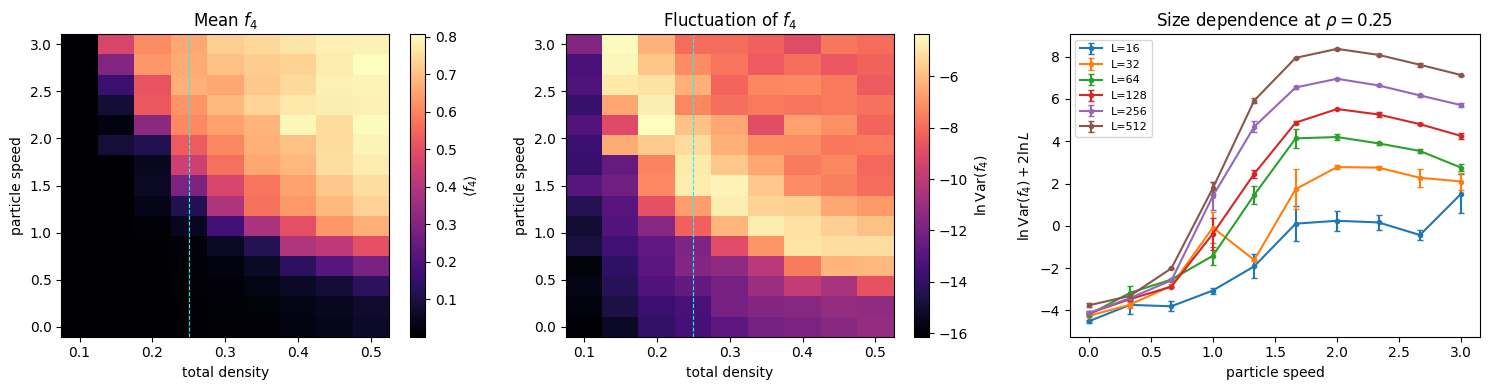

In [22]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, data, title, label in zip(ax[:2], [means, log_variances],
                                  [r'Mean $f_4$', r'Fluctuation of $f_4$'],
                                  [r'$\langle f_4\rangle$', r'$\ln\operatorname{Var}(f_4)$']):
    im = a.pcolormesh(densities, speeds, data, shading='nearest', cmap='magma')
    a.axvline(size_density, color='cyan', ls='--', lw=.8)
    a.set(xlabel='total density', ylabel='particle speed', title=title)
    fig.colorbar(im, ax=a, label=label)
for i, size in enumerate(sizes):
    ax[2].errorbar(size_speeds, size_log_variances[i] + 2*np.log(size),
                   yerr=size_log_errors[i], marker='o', ms=3,
                   capsize=2, label=f'L={size}')
ax[2].set(xlabel='particle speed', ylabel=r'$\ln\operatorname{Var}(f_4) + 2 \ln L$',
          title=fr'Size dependence at $\rho={size_density}$')
ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()